# Tuning stay_point v_2 (trên `dev`)

v_2 giống v_1, chỉ khác **neo của stay**: v_1 dùng điểm đầu (cố định), v_2 dùng **tâm** (trung bình lat, lon, mỗi điểm nặng như nhau)
của các điểm đã nhận vào stay, tính lại sau mỗi điểm được nhận. Thời gian không đổi: stay bắt đầu ở điểm đầu, T đo từ đó.

Chọn tham số của [`config.yaml`](config.yaml) bằng **đúng quy trình và quy tắc chọn của v_1**
([`docs/models/stay_point_v1.md`](../../../docs/models/stay_point_v1.md)); các phép đo nằm ở `src/geolife/tuning/stay_point.py` và `src/geolife/tuning/common.py`, dùng chung cho mọi version.
Diễn giải: [`docs/models/stay_point_v2.md`](../../../docs/models/stay_point_v2.md).

- Chỉ chạy trên `dev`. `holdout` không được mở trong notebook này.
- Không so sánh với v_1 ở đây; so sánh / đánh giá làm sau.

| Bước | Tham số |
| --- | --- |
| B1 | Khoảng ứng viên của D (từ EDA, dùng lại của v_1) |
| B2 | Số stay theo (D, T) |
| B3 | T |
| B4 | D |
| B5 | max_gap |
| B6 | Khung đêm, khung hành chính |
| B7 | place_eps |
| B8 | min_nights, min_workdays |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from geolife import io
from geolife.tuning import common as tu, stay_point as tsp
from geolife.evaluation import label_flags
from geolife.models import load_model
from geolife.models.stay_point import detect_stays

pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "axes.titleweight": "bold"})

base = load_model("stay_point", 2)
P, DV, ANCHOR = base.params, base.data_version, base.params["anchor"]
users = io.split_users(DV, "dev")
pts = io.load_points(DV, users=users)
flags = label_flags(pts, io.load_labels(DV))
print(f"dev: {len(users)} user, {len(pts):,} điểm, {flags.labeled.sum():,} điểm có nhãn | anchor = {ANCHOR}")

dev: 135 user, 18,452,398 điểm, 3,575,085 điểm có nhãn | anchor = centroid


## B1. Khoảng ứng viên của D

Dùng lại nguyên B1 của v_1 vì đây là dữ liệu thô, không phụ thuộc cách đặt neo: EDA mục 14 cho bán kính p90 khi đứng yên
p50 = 16 m, p90 = 71 m, p95 = 149 m, p99 = 746 m.

**⇒ Ứng viên:** D ∈ {50, 100, 200, 300} m.

## B2. Khả năng tạo stay khi thay đổi D và T

**Định nghĩa:** số stay trên mỗi (user, ngày) có dữ liệu. max_gap giữ ở 24 h, chọn lại ở B5.

In [2]:
grid = tsp.stay_grid(pts, flags, [50, 100, 200, 300], [5, 10, 20, 30, 60], 24, ANCHOR)
display(grid.pivot(index="D_m", columns="T_min", values="n_stays"))
display(grid.pivot(index="D_m", columns="T_min", values="stays_per_day").round(2))

T_min,5,10,20,30,60
D_m,,,,,
50,33048,18172,10397,7692,4814
100,41461,23855,14959,11674,7800
200,49112,28830,19507,15955,11347
300,46639,30470,21243,17884,13253


T_min,5,10,20,30,60
D_m,,,,,
50,3.53,1.94,1.11,0.82,0.51
100,4.43,2.55,1.60,1.25,0.83
200,5.25,3.08,2.08,1.70,1.21
300,4.98,3.26,2.27,1.91,1.42


**Output cho thấy:**
- Như v_1, số stay nhạy với T hơn nhiều so với D: tăng T từ 5 lên 60 phút làm số stay / ngày giảm 3,5–7 lần.
- Ở T = 5 phút có 3,5–5,2 stay mỗi ngày: quá nhiều so với nhịp sống bình thường.
- Khác v_1: ở T = 5, D = 300 tạo **ít** stay hơn D = 200 (4,98 so với 5,25 stay / ngày). Neo tâm đi theo các điểm, nên với bán kính lớn
  nhiều mảnh ngắn được nối thành một stay dài hơn.

⇒ Chọn T trước (B3), rồi mới chọn D (B4).

## B3. Chọn T: tỉ lệ stay giả

**Định nghĩa:** như v_1. Stay giả = stay trong vùng có nhãn (≥ 50% số điểm có nhãn) mà ≥ 50% số điểm mang nhãn di chuyển
(phương tiện di chuyển, không tính `walk`).

**Quy tắc chọn (của v_1):** T lớn nhất trước khi stay giả bắt đầu tăng.

T_min,5,10,20,30,60
D_m,,,,,
100,44.1%,43.0%,42.1%,44.1%,47.6%
200,50.0%,46.8%,47.3%,48.8%,52.8%


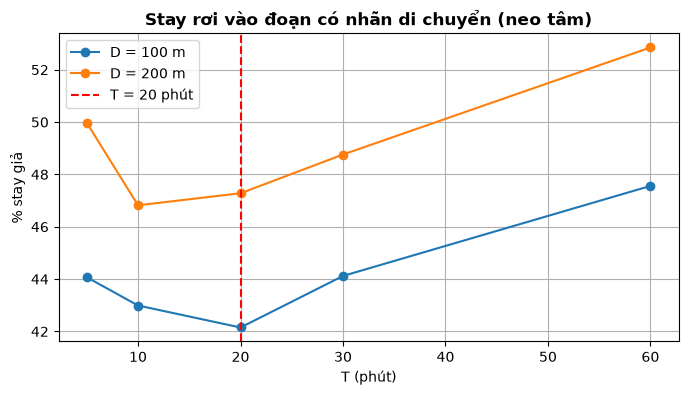

In [3]:
sub = grid[grid.D_m.isin([100, 200])]
display(sub.pivot(index="D_m", columns="T_min", values="fake_share").map("{:.1%}".format))
fig, ax = plt.subplots(figsize=(8, 4))
for D, g in sub.groupby("D_m"):
    ax.plot(g.T_min, g.fake_share * 100, "o-", label=f"D = {D} m")
ax.axvline(P["T_min"], color="r", ls="--", label=f"T = {P['T_min']} phút")
ax.set(xlabel="T (phút)", ylabel="% stay giả", title="Stay rơi vào đoạn có nhãn di chuyển (neo tâm)"); ax.legend(); plt.show()

**Output cho thấy:**
- Như v_1, mức stay giả cao (42–53%) vì nhãn nhiễu; chỉ dùng để so sánh giữa các T.
- Từ T = 10 đến T = 20 stay giả gần như **không đổi** (D = 100: 43,0% → 42,1%; D = 200: 46,8% → 47,3%), chênh dưới 1 điểm %.
- Từ T = 30 trở đi stay giả **tăng rõ** (D = 200: 48,8% ở 30 phút, 52,8% ở 60 phút).

**⇒ Chọn T = 20 phút** (như v_1): giá trị lớn nhất trước khi stay giả bắt đầu tăng.

## B4. Chọn D: phân mảnh, stay giả và stay dài

**Định nghĩa:** như v_1, với T = 20: `fragment_share`, `fake_share`, `long_stays` (stay ≥ 6 giờ), và số user có home / office trên `dev`.

In [4]:
T = P["T_min"]
d_tab = grid[grid.T_min == T].set_index("D_m")[["stays_per_day", "fragment_share", "fake_share", "long_stays"]]
d_tab["long_change"] = d_tab.long_stays.pct_change()
for D in [100, 200, 300]:
    _, pred = load_model("stay_point", 2, D_m=D).predict(pts)
    n = pred.groupby("role").lat.count()
    d_tab.loc[D, "home_found"], d_tab.loc[D, "office_found"] = n["home"], n["office"]
display(d_tab.style.format({"stays_per_day": "{:.2f}", "fragment_share": "{:.1%}", "fake_share": "{:.1%}",
                            "long_change": "{:+.0%}", "home_found": "{:.0f}", "office_found": "{:.0f}"}, na_rep="-"))

,stays_per_day,fragment_share,fake_share,long_stays,long_change,home_found,office_found
D_m,,,,,,,
50,1.11,13.1%,41.2%,1624,-,-,-
100,1.60,11.4%,42.1%,2942,+81%,77,60
200,2.08,8.3%,47.3%,4728,+61%,87,78
300,2.27,5.7%,51.5%,5710,+21%,93,77


**Output cho thấy:**
- Phân mảnh giảm mạnh hơn v_1 khi tăng D (13,1% → 5,7% từ 50 lên 300 m).
- Stay giả gần như không đổi tới 100 m (41,2% → 42,1%), rồi tăng khoảng 4–5 điểm % mỗi bước (47,3% ở 200 m, 51,5% ở 300 m).
- Số stay dài tăng mạnh tới 200 m (2.942 → 4.728, +61%), sau đó chậm lại (→ 5.710 ở 300 m, +21%).
  User có home / office: 77 / 60 ở D = 100, 87 / 78 ở D = 200, 93 / 77 ở D = 300.

**⇒ Chọn D = 200 m** (như v_1): đổi 5,1 điểm % stay giả lấy thêm hơn một nửa số stay dài. Lên 300 m lợi ích về stay dài nhỏ dần (+21%)
và office không tăng, trong khi stay giả vẫn tăng cùng mức.

## B5. Chọn max_gap

**Định nghĩa:** như v_1. (1) % cặp điểm liên tiếp có khoảng không ghi ≥ 10 phút mà điểm sau cách điểm trước ≤ D. (2) Chỉ số stay theo max_gap.
Bảng (1) chỉ dùng dữ liệu điểm, không phụ thuộc neo, nên trùng v_1.

In [5]:
D = P["D_m"]
display(tu.gap_return_table(pts, D).style.format({"back_share": "{:.1%}"}))
display(tsp.max_gap_table(pts, flags, D, T, [6, 12, 24, 48, 72, 1e6], ANCHOR)[["stays_per_day", "fragment_share", "fake_share", "long_stays"]]
        .style.format({"fragment_share": "{:.1%}", "fake_share": "{:.1%}", "stays_per_day": "{:.2f}"}))

,gaps,back_share
bin,,
10'-1h,14174,72.0%
1-3h,5329,61.0%
3-6h,2749,47.3%
6-12h,5149,44.4%
12-24h,4781,31.8%
24-48h,1163,22.4%
48-72h,339,18.6%
3-7 ngày,384,18.0%
> 7 ngày,307,17.6%


,stays_per_day,fragment_share,fake_share,long_stays
max_gap_h,,,,
6.000000,1.65,9.5%,42.1%,216
12.000000,1.91,8.6%,45.8%,2863
24.000000,2.08,8.3%,47.3%,4728
48.000000,2.11,8.3%,47.2%,5016
72.000000,2.12,8.3%,47.2%,5087
1000000.000000,2.13,8.3%,47.2%,5224


**Output cho thấy:**
- Tỉ lệ quay lại đúng chỗ giảm tới 22% ở 24–48 h rồi đứng yên quanh 18–22% (mức "tình cờ"), như v_1.
- Chỉ số stay bão hoà sau 24 h: tăng lên 48 h chỉ thêm 6% số stay dài (4.728 → 5.016); phân mảnh và stay giả không đổi (8,3%, 47,3% → 47,2%).
  Hạ xuống 12 h làm mất 39% số stay dài (→ 2.863).

**⇒ Chọn max_gap = 24 h** (như v_1).

## B6. Khung đêm và khung hành chính

**Định nghĩa và quy tắc chọn:** như v_1. Khung đêm = giờ được ≥ 60% số stay qua đêm phủ; khung hành chính = giờ được ≥ 40% số stay ban ngày
của ngày làm việc phủ.

Stay qua đêm: 3044 stay của 80 user
Stay ban ngày, ngày làm việc: 1741 stay của 63 user


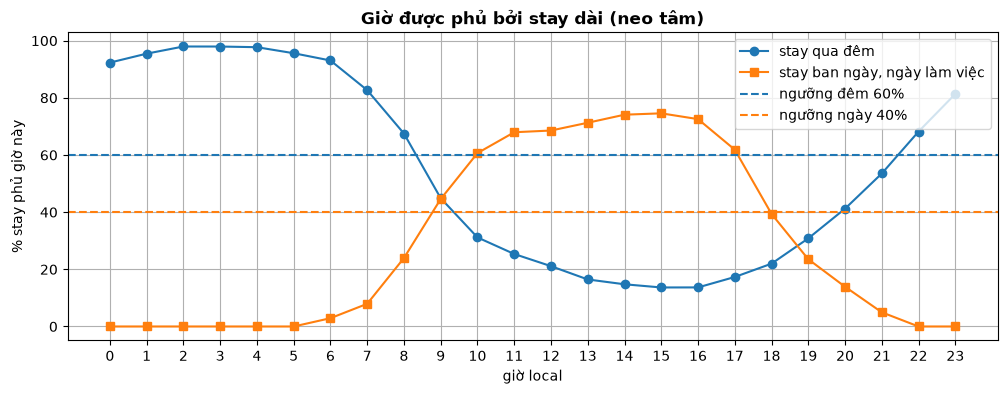

hour,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
qua đêm,92,95,98,98,98,96,93,83,67,45,...,15,14,14,17,22,31,41,54,68,81
"ban ngày, ngày làm việc",0,0,0,0,0,0,3,8,24,45,...,74,75,73,62,39,24,14,5,0,0


Khung đêm: [22, 9] | khung hành chính: [9, 18]
Config: [22, 9] [9, 18]


In [6]:
stays = detect_stays(pts, D, T, P["max_gap_h"], ANCHOR)
cov, counts = tu.window_coverage(stays)
for k, (ns, nu) in counts.items():
    print(f"Stay {k}: {ns} stay của {nu} user")
NIGHT_MIN, DAY_MIN = 0.6, 0.4
fig, ax = plt.subplots(figsize=(12, 4))
for c, m in zip(cov.columns, ["o-", "s-"]):
    ax.plot(cov.index, cov[c] * 100, m, label=f"stay {c}")
ax.axhline(NIGHT_MIN * 100, color="C0", ls="--", label="ngưỡng đêm 60%")
ax.axhline(DAY_MIN * 100, color="C1", ls="--", label="ngưỡng ngày 40%")
ax.set(xlabel="giờ local", ylabel="% stay phủ giờ này", xticks=range(24), title="Giờ được phủ bởi stay dài (neo tâm)"); ax.legend(); plt.show()
display((cov.T * 100).round(0).astype(int))
night_h = [h for h in range(24) if cov["qua đêm"][h] >= NIGHT_MIN]
day_h = [h for h in range(24) if cov["ban ngày, ngày làm việc"][h] >= DAY_MIN]
print("Khung đêm:", tu.hours_to_window(night_h), "| khung hành chính:", tu.hours_to_window(day_h))
print("Config:", P["night_hours"], P["work_hours"])

**Output cho thấy:** đường phủ gần như trùng v_1 (lệch ≤ 4 điểm % ở mọi giờ). Giờ đạt ngưỡng 60% của stay qua đêm là 22:00 (68%) tới hết
08:00 (67%); giờ đạt ngưỡng 40% của stay ban ngày là 09:00 (45%) tới hết 17:00 (62%).

**⇒ Chọn:** khung đêm **[22, 9)**, mọi ngày; khung hành chính **[9, 18)**, chỉ ngày làm việc (như v_1).

## B7. Chọn place_eps

**Định nghĩa và quy tắc chọn:** như v_1. Số place / user, số user có home / office, và % user có home / office dịch > 200 m so với
place_eps liền trước. Chọn ở chỗ thay đổi so với giá trị liền trước nhỏ nhất cho cả home và office, khi số user có home đã chạm trần.

In [7]:
model = load_model("stay_point", 2)
display(tsp.place_eps_table(model, stays, users, [50, 100, 200, 300, 500])
        .style.format({"home_moved_vs_prev": "{:.1%}", "office_moved_vs_prev": "{:.1%}", "places_per_user": "{:.0f}"}, na_rep="-"))

,places_per_user,home_found,office_found,home_moved_vs_prev,office_moved_vs_prev
eps_m,,,,,
50,26,76,52,-,-
100,20,82,60,3.9%,7.7%
200,16,86,75,6.1%,8.5%
300,14,87,78,4.7%,5.4%
500,11,88,73,5.7%,8.2%


**Output cho thấy:**
- 50 m chia một nơi thành nhiều place: chỉ 76 user có home, 52 user có office.
- Khác v_1, bước 100 → 200 m **chưa** ổn định (home dịch 6,1%, office 8,5%). Neo tâm cho các stay của cùng một nơi nằm tản hơn quanh
  nơi đó, nên cần bán kính gom lớn hơn để gom chúng lại.
- Bước 200 → 300 m ổn định nhất cho cả hai vai trò (home 4,7%, office 5,4%), và số user có home đã chạm trần (86 → 87 → 88).
- Lên 500 m thì cả hai lại dịch nhiều hơn (5,7%, 8,2%).

**⇒ Chọn place_eps = 300 m** (v_1: 200 m).

## B8. Cần bao nhiêu đêm / ngày làm việc?

**Định nghĩa và quy tắc chọn:** như v_1, dùng các tham số đã chọn ở B1–B7. Chọn k nhỏ nhất mà cả home và office đều trùng mốc ≥ 60%.

In [8]:
mt = tu.min_days_agreement(model, stays, users)
display(mt.groupby(["role", "k"]).agg(users=("user", "nunique"), match=("match", "mean")).unstack("role")
        .style.format({("match", "home"): "{:.0%}", ("match", "office"): "{:.0%}"}))

**Output cho thấy:** 1 ngày chỉ trùng 50%; 2 ngày: 59% home, 61% office; 3 ngày: 64% home, 67% office; 10 ngày: 85% / 81%.

**⇒ Chọn min_nights = min_workdays = 3** (như v_1): mốc đầu tiên mà cả hai vai trò đều trùng ≥ 60%.

## Tổng kết

| Tham số | v_2 | Khác v_1? |
| --- | --- | --- |
| anchor | centroid | có |
| D / T / max_gap | 200 m / 20 phút / 24 h | không |
| Khung đêm / hành chính | [22, 9) / [9, 18) | không |
| place_eps | 300 m | có (v_1: 200 m) |
| min_nights / min_workdays | 3 / 3 | không |

Chạy cuối cùng trên `holdout` (một lần):

```bash
uv run python -m geolife.run --model stay_point --version 2 --split holdout
```

In [9]:
print(base.params)

{'anchor': 'centroid', 'D_m': 200, 'T_min': 20, 'max_gap_h': 24, 'place_eps_m': 300, 'night_hours': [22, 9], 'work_hours': [9, 18], 'min_nights': 3, 'min_workdays': 3, 'same_place_m': 200, 'confidence': {'n_boot': 200, 'block': 'week', 'seed': 0}}
